# CityPulse AI — February forecasting-data preparation

Our full project will connect data engineering, forecasting, MLOps, agentic AI, and statistical analytics. This notebook implements **Phase 2.1 only**: preparing time series before training models.

A **time series** is a sequence of measurements ordered by time. Here our target is the number of validated ride starts per hour. It measures realized rides, not all potential demand: unavailable bikes or closed stations can prevent trips.

We use the reviewed February 2025 outputs, not raw CSVs. The canonical warehouse retains January 31 starts; the February view includes only local starts in `[February 1, March 1)`. Stored timestamps remain UTC. We do not change the Phase 1 ETL or the existing EDA notebook.

## 1. Find the project and import our tools

`pathlib` handles file paths. `pandas` reads the prepared Parquet tables, and `matplotlib` draws plots. The small path setup lets imports work when Jupyter starts in either the project root or `notebooks/`. Run the preparation command in the README first if the outputs are missing.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "src/citypulse_ai").exists():
    raise FileNotFoundError("Open this notebook from the project root or notebooks/ directory")
sys.path.insert(0, str(ROOT / "src"))
from citypulse_ai.features.preparation import prepare_hourly

OUTPUT = ROOT / "outputs/phase21-forecasting"
if not (OUTPUT / "report.json").exists():
    raise FileNotFoundError("Run the Phase 2.1 preparation command in README.md first")
report = json.loads((OUTPUT / "report.json").read_text())
city = pd.read_parquet(OUTPUT / "citywide_hourly.parquet")
coverage = pd.read_parquet(OUTPUT / "station_coverage.parquet")
gaps = pd.read_parquet(OUTPUT / "coverage_gaps.parquet")
periods = pd.read_parquet(OUTPUT / "activity_periods.parquet")
pd.Series({key: report[key] for key in ["observed_ride_starts", "citywide_hours", "stations", "training_stations", "observed_station_hours", "unknown_station_hours", "station_policy"]}, name="Verified preparation")

observed_ride_starts                      2030269
citywide_hours                                672
stations                                     2237
training_stations                            2224
observed_station_hours                     598630
unknown_station_hours                      904634
station_policy            unknown_unless_observed
Name: Verified preparation, dtype: object

## 2. Check the citywide calendar and chronological splits

Citywide totals combine all stations. The complete monthly source was reconciled, so an absent citywide hour could be an explicitly flagged zero. **This month has no missing citywide hours, so no citywide zeros were inserted.**

We split by NYC local dates: February 1–20 for training, 21–24 for validation, and 25–28 for testing. Every station shares the same boundaries. Training learns from the past; validation supports later model choices; test data stays reserved for final evaluation. Calendar features are known in advance and require no fitted statistics.

In [2]:
display(city.head())
split_summary = city.groupby("split", sort=False).agg(hours=("hour_start", "size"), ride_starts=("ride_count", "sum"))
display(split_summary)
assert city.ride_count.sum() == report["observed_ride_starts"]
assert len(city) == 672 and not city.hour_start.duplicated().any()

,hour_start,ride_count,ride_count_observed,is_zero_filled,coverage_status,hour,weekday,is_weekend,split
0,2025-02-01 05:00:00+00:00,1534,1534,False,observed,0,5,True,train
1,2025-02-01 06:00:00+00:00,1070,1070,False,observed,1,5,True,train
2,2025-02-01 07:00:00+00:00,765,765,False,observed,2,5,True,train
3,2025-02-01 08:00:00+00:00,491,491,False,observed,3,5,True,train
4,2025-02-01 09:00:00+00:00,335,335,False,observed,4,5,True,train


,hours,ride_starts
split,,
train,480,1309480
validation,96,286095
test,96,434694


## 3. Visualize hourly citywide ride starts

We convert timestamps to NYC time for labels. The colored regions show the chronological split rather than a random split, which would mix future information into training.

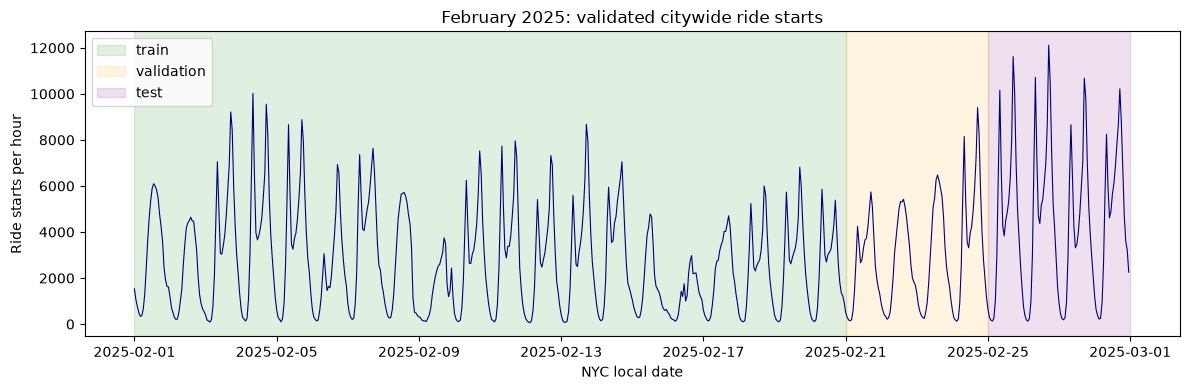

In [3]:
local_hours = city.hour_start.dt.tz_convert("America/New_York")
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(local_hours, city.ride_count, linewidth=0.8, color="navy")
for label, color in [("train", "green"), ("validation", "orange"), ("test", "purple")]:
    section = city[city["split"].eq(label)].hour_start.dt.tz_convert("America/New_York")
    ax.axvspan(section.min(), section.max() + pd.Timedelta(hours=1), alpha=0.12, color=color, label=label)
ax.set(title="February 2025: validated citywide ride starts", xlabel="NYC local date", ylabel="Ride starts per hour")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Investigate station coverage and no-record periods

An **observed hour** has at least one validated start. A missing row can mean no rides, an unavailable station, a source issue, or an identifier change. Trip logs alone cannot distinguish these explanations. We call these *no-record periods*, not confirmed station closures.

Activity episodes group observed hours separated by fewer than 24 consecutive no-record hours. They are retrospective descriptions, not operating schedules or model features. Stations seen during training form the future model cohort; stations first seen during validation/test stay in the audit but require a separate cold-start strategy. We do not use full-month coverage thresholds to select training stations.

,observed_hours,missing_hours,ride_starts,longest_no_record_hours
count,2237.000000,2237.000000,2237.000000,2237.000000
mean,267.603934,404.396066,907.585606,42.881985
std,171.308368,171.308368,1155.520185,81.537969
min,1.000000,53.000000,1.000000,3.000000
25%,108.000000,246.000000,133.000000,11.000000
50%,251.000000,421.000000,381.000000,18.000000
75%,426.000000,564.000000,1297.000000,37.000000
max,619.000000,671.000000,8811.000000,663.000000


,intervals,missing_hours
position,,
after_last_observation,1281,8067
before_first_observation,1496,49401
between_observations,182989,847166


,start_station_id,first_observed_utc,ride_starts
32,3113.1,2025-02-24 17:00:00+00:00,2
109,3391.1,2025-02-27 15:00:00+00:00,1
316,4129.1,2025-02-28 16:00:00+00:00,1
431,4432.1,2025-02-23 03:00:00+00:00,6
569,4798.1,2025-02-28 20:00:00+00:00,1
1247,6380.1,2025-02-22 23:00:00+00:00,3
1364,6596.1,2025-02-23 18:00:00+00:00,1
1505,6869.1,2025-02-28 03:00:00+00:00,1
1530,6923.2,2025-02-21 14:00:00+00:00,10
1842,7883.1,2025-02-21 22:00:00+00:00,1


,start_station_id,start_utc,end_utc_exclusive,observed_hours,ride_starts
0,2733.03,2025-02-01 16:00:00+00:00,2025-02-01 17:00:00+00:00,1,1
1,2733.03,2025-02-03 12:00:00+00:00,2025-02-05 13:00:00+00:00,5,6
2,2733.03,2025-02-06 23:00:00+00:00,2025-02-09 23:00:00+00:00,7,9
3,2733.03,2025-02-13 00:00:00+00:00,2025-02-13 01:00:00+00:00,1,1
4,2733.03,2025-02-14 12:00:00+00:00,2025-02-15 17:00:00+00:00,6,6


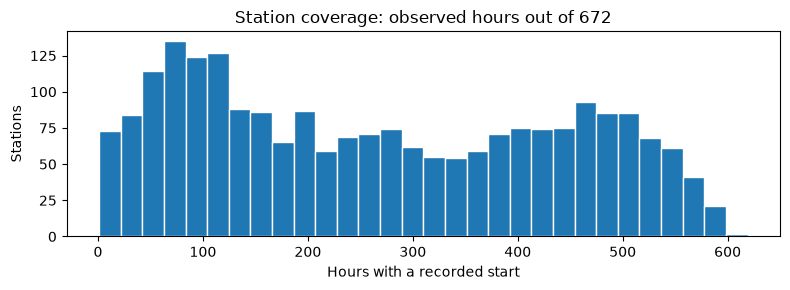

In [4]:
display(coverage[["observed_hours", "missing_hours", "ride_starts", "longest_no_record_hours"]].describe())
display(gaps.groupby("position").agg(intervals=("hours", "size"), missing_hours=("hours", "sum")))
display(coverage[~coverage.training_station][["start_station_id", "first_observed_utc", "ride_starts"]])
display(periods.head())
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(coverage.observed_hours, bins=30, edgecolor="white")
ax.set(title="Station coverage: observed hours out of 672", xlabel="Hours with a recorded start", ylabel="Stations")
fig.tight_layout()
plt.show()

## 5. Inspect one station without treating unknown hours as zeros

Parquet column filters load only the chosen station. We pick a training-seen station with median coverage for illustration; this choice is for visualization only, not model selection. Gaps in the plotted line are unknown labels. Both `6569.09_` and `6569.09` remain distinct identifiers.

,start_station_id,hour_start,ride_count,coverage_status,split
0,3822.08,2025-02-01 05:00:00+00:00,<NA>,unknown,train
1,3822.08,2025-02-01 06:00:00+00:00,1,observed,train
2,3822.08,2025-02-01 07:00:00+00:00,<NA>,unknown,train
3,3822.08,2025-02-01 08:00:00+00:00,<NA>,unknown,train
4,3822.08,2025-02-01 09:00:00+00:00,<NA>,unknown,train
5,3822.08,2025-02-01 10:00:00+00:00,1,observed,train
6,3822.08,2025-02-01 11:00:00+00:00,<NA>,unknown,train
7,3822.08,2025-02-01 12:00:00+00:00,1,observed,train
8,3822.08,2025-02-01 13:00:00+00:00,<NA>,unknown,train
9,3822.08,2025-02-01 14:00:00+00:00,<NA>,unknown,train


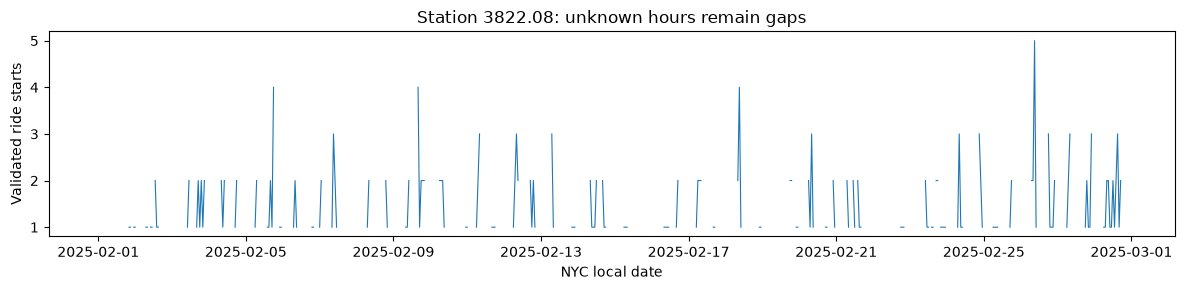

In [5]:
training_coverage = coverage[coverage.training_station].sort_values("observed_hours")
station_id = training_coverage.iloc[len(training_coverage) // 2].start_station_id
station = pd.read_parquet(OUTPUT / "station_hourly.parquet", filters=[("start_station_id", "==", station_id)])
display(station[["start_station_id", "hour_start", "ride_count", "coverage_status", "split"]].head(12))
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(station.hour_start.dt.tz_convert("America/New_York"), station.ride_count.to_numpy(dtype=float, na_value=float("nan")), linewidth=0.8)
ax.set(title=f"Station {station_id}: unknown hours remain gaps", xlabel="NYC local date", ylabel="Validated ride starts")
fig.tight_layout()
plt.show()

## 6. Understand an optional zero assumption

The default exported station dataset retains unknowns. For comparison only, the opt-in rule below assumes zero within **24 hours after a past recorded start** at a training-seen station, when the monthly source is confirmed complete. It never fills before the first observation and leaves longer silences unknown. The 24-hour horizon is a sensitivity scenario, **not a proven operating rule**. Such zeros are flagged so later experiments can compare policies.

This demonstration prepares just the selected station from already reviewed hourly counts. It does not overwrite the default files. A later model must mask unknown targets explicitly; simply dropping them or treating them as zeros can bias evaluation.

In [6]:
observed_station = station.loc[station.ride_count_observed.notna(), ["start_station_id", "hour_start", "ride_count_observed"]].rename(columns={"ride_count_observed": "ride_count"})
scenario = prepare_hourly(observed_station, source_complete=True, station_zero_horizon=24).station_hourly
display(pd.DataFrame({
    "policy": ["default unknown", "optional recent-activity zeros"],
    "unknown_hours": [int(station.ride_count.isna().sum()), int(scenario.ride_count.isna().sum())],
    "assumed_zero_hours": [int(station.is_zero_filled.sum()), int(scenario.is_zero_filled.sum())],
    "ride_starts": [int(station.ride_count.sum()), int(scenario.ride_count.sum())],
}))
assert station.ride_count.sum() == scenario.ride_count.sum()

,policy,unknown_hours,assumed_zero_hours,ride_starts
0,default unknown,420,0,381
1,optional recent-activity zeros,1,419,381


## 7. What this dataset can and cannot tell us

February provides only 28 days, with 20 training days and short 4-day validation/test periods. It cannot establish annual seasonality, summer demand, holiday effects, or robust model rankings. These splits are provisional; later backtesting should span full weeks and multiple seasons.

Before models: review no-record periods with historical station availability/maintenance records, choose a target-coverage policy explicitly, and plan at least 12 complete months (preferably 24) with checksums, source completeness checks, global ride-ID auditing, reviewed identifier mappings, and DST-safe UTC hours. Learn station eligibility, scaling, and any learned features from training history only. Later time folds must never use future coverage or future realized weather.

The full roadmap remains ARIMA/XGBoost, PyTorch/TensorFlow with LSTM/TFT, MLflow and monitoring, QLoRA on H100, LangGraph/MCP/vLLM, FastAPI, Docker/Kubernetes/GitHub Actions, AWS/Google Cloud, and statistical/A/B reporting. We have not trained any model here.